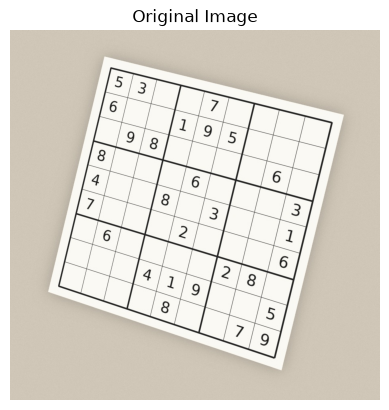

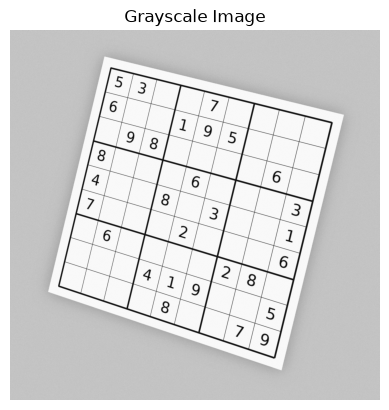

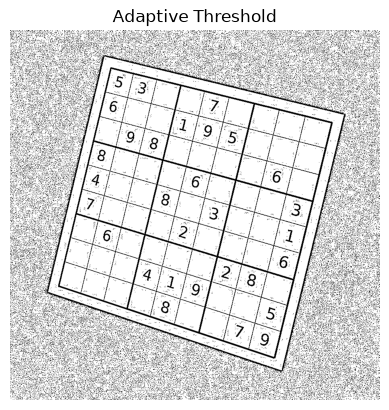

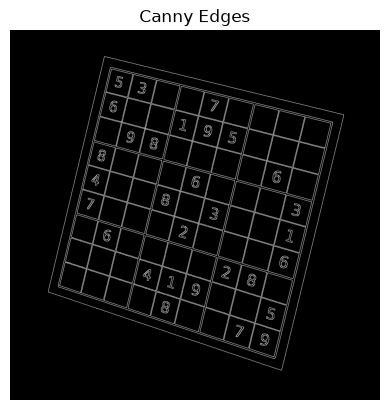

sudoku grid found
grid area: 384332.0


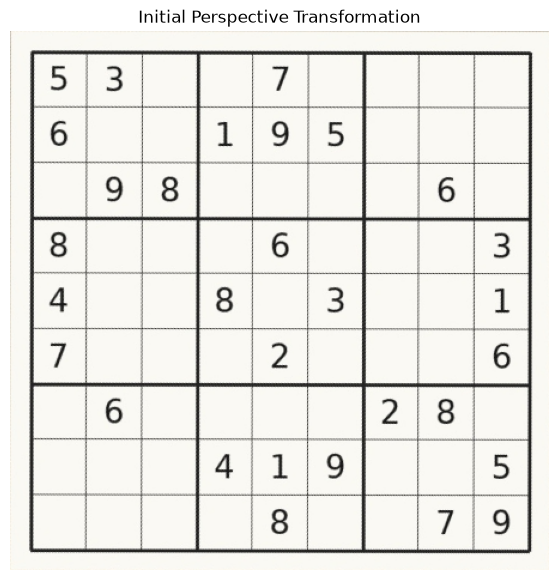


Detected Sudoku board:
Left: 17, Right: 436
Top: 16, Bottom: 436
Detected size: 419 x 420


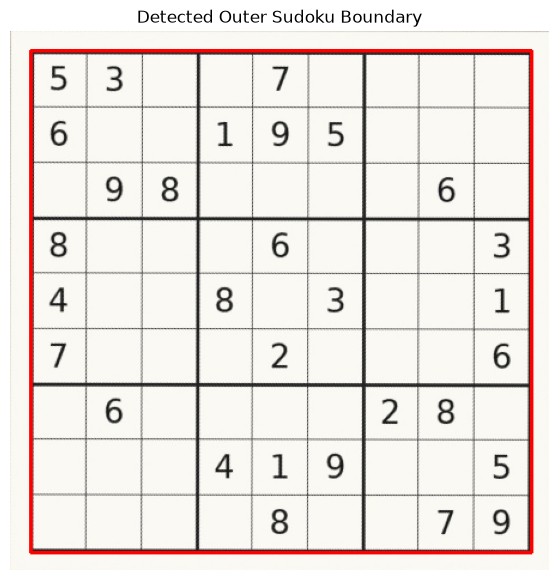

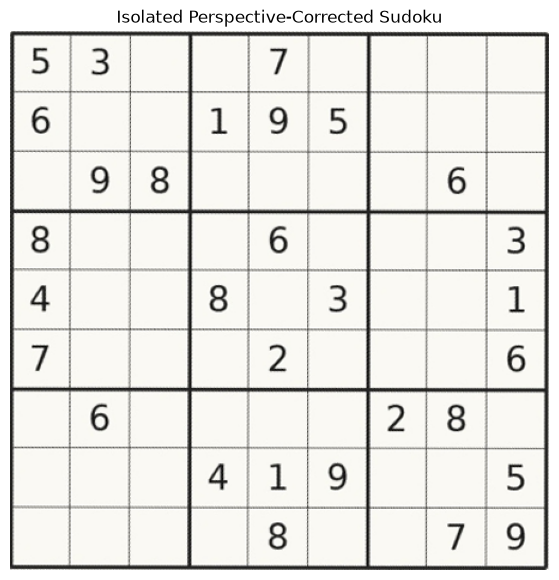

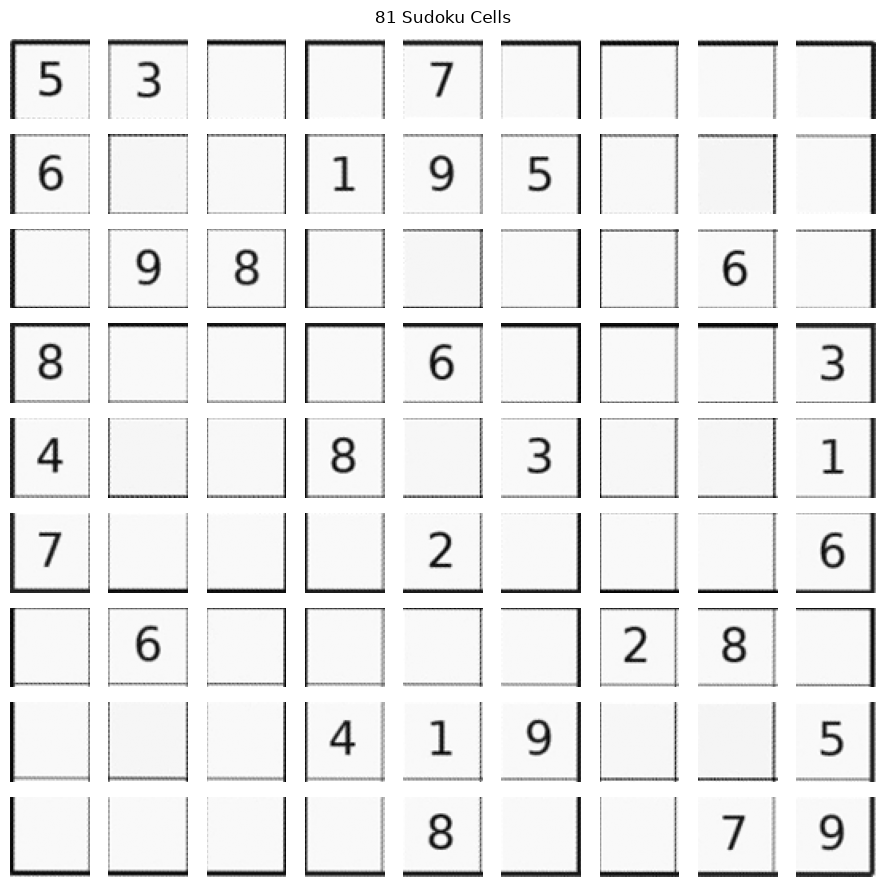

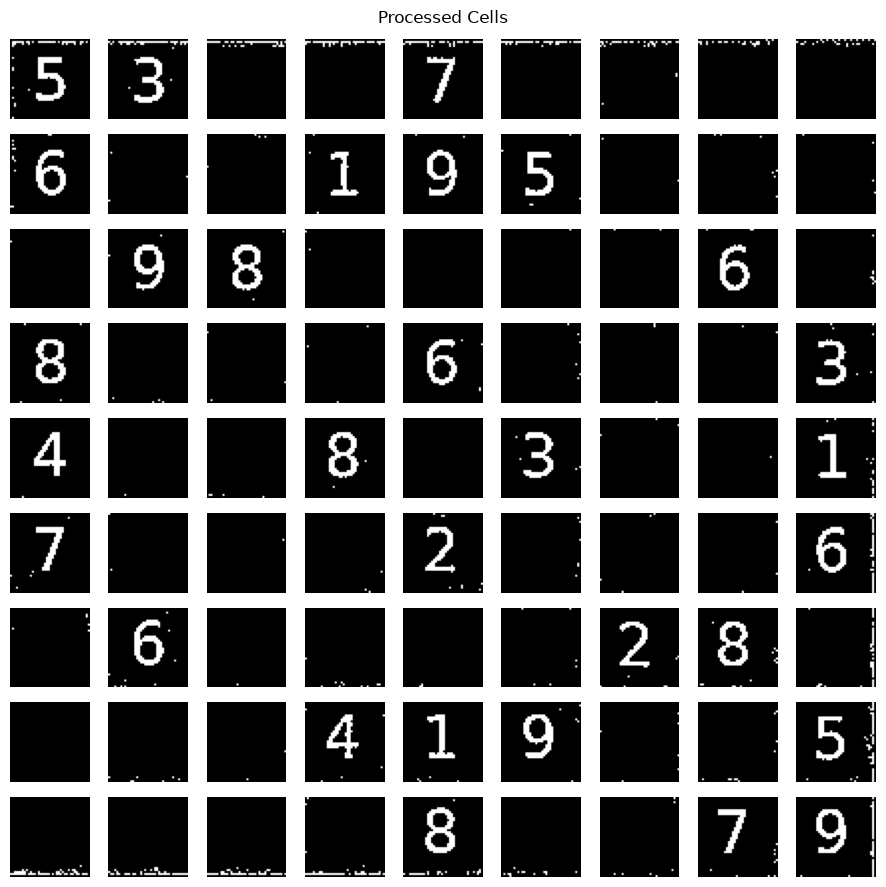

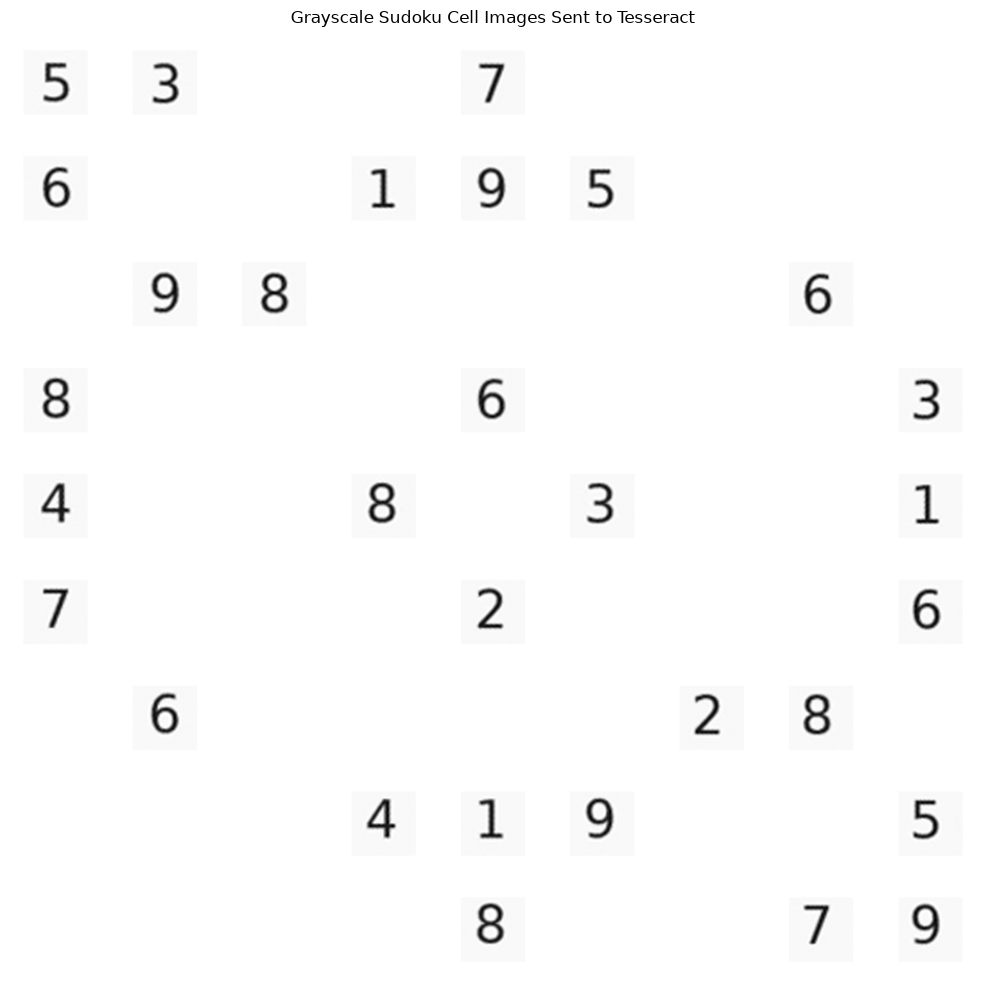


Recognised Sudoku:
0 = empty or unrecognised cell

[5, 3, 0, 0, 7, 0, 0, 0, 0]
[6, 0, 0, 1, 9, 5, 0, 0, 0]
[0, 9, 8, 0, 0, 0, 0, 6, 0]
[8, 0, 0, 0, 6, 0, 0, 0, 3]
[4, 0, 0, 8, 0, 3, 0, 0, 1]
[7, 0, 0, 0, 2, 0, 0, 0, 6]
[0, 6, 0, 0, 0, 0, 2, 8, 0]
[0, 0, 0, 4, 1, 9, 0, 0, 5]
[0, 0, 0, 0, 8, 0, 0, 7, 9]

Recognised 30 out of 81 cells.

Empty or unrecognised cells:
Row 1, column 3
Row 1, column 4
Row 1, column 6
Row 1, column 7
Row 1, column 8
Row 1, column 9
Row 2, column 2
Row 2, column 3
Row 2, column 7
Row 2, column 8
Row 2, column 9
Row 3, column 1
Row 3, column 4
Row 3, column 5
Row 3, column 6
Row 3, column 7
Row 3, column 9
Row 4, column 2
Row 4, column 3
Row 4, column 4
Row 4, column 6
Row 4, column 7
Row 4, column 8
Row 5, column 2
Row 5, column 3
Row 5, column 5
Row 5, column 7
Row 5, column 8
Row 6, column 2
Row 6, column 3
Row 6, column 4
Row 6, column 6
Row 6, column 7
Row 6, column 8
Row 7, column 1
Row 7, column 3
Row 7, column 4
Row 7, column 5
Row 7, column 6
Row 7, col

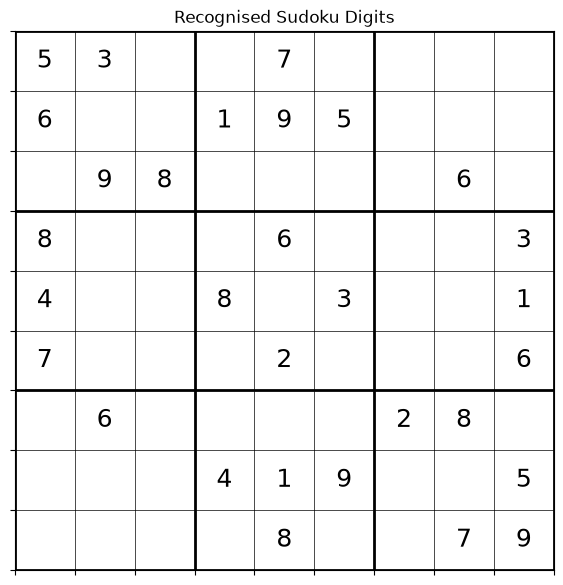


Foreground pixel count for each cell (empty-cell threshold = 60):

Row 1, Column 1: 195 pixels
Row 1, Column 2: 188 pixels
Row 1, Column 3: 46 pixels
Row 1, Column 4: 46 pixels
Row 1, Column 5: 139 pixels
Row 1, Column 6: 40 pixels
Row 1, Column 7: 37 pixels
Row 1, Column 8: 27 pixels
Row 1, Column 9: 26 pixels
Row 2, Column 1: 175 pixels
Row 2, Column 2: 3 pixels
Row 2, Column 3: 4 pixels
Row 2, Column 4: 112 pixels
Row 2, Column 5: 160 pixels
Row 2, Column 6: 148 pixels
Row 2, Column 7: 2 pixels
Row 2, Column 8: 7 pixels
Row 2, Column 9: 4 pixels
Row 3, Column 1: 1 pixels
Row 3, Column 2: 165 pixels
Row 3, Column 3: 178 pixels
Row 3, Column 4: 2 pixels
Row 3, Column 5: 0 pixels
Row 3, Column 6: 1 pixels
Row 3, Column 7: 2 pixels
Row 3, Column 8: 160 pixels
Row 3, Column 9: 8 pixels
Row 4, Column 1: 176 pixels
Row 4, Column 2: 4 pixels
Row 4, Column 3: 3 pixels
Row 4, Column 4: 3 pixels
Row 4, Column 5: 163 pixels
Row 4, Column 6: 6 pixels
Row 4, Column 7: 3 pixels
Row 4, Column 8: 2

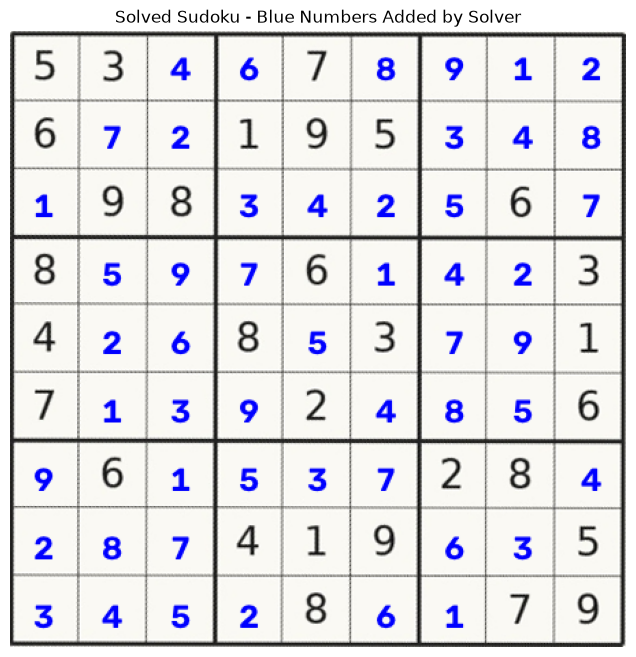

In [8]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pytesseract
import time

# Set the Tesseract executable path for Windows
pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

# load the image
image = cv2.imread("sudoku_strong_perspective.jpg")

if image is None:
    print("could not load image")
    raise SystemExit

# display original image
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Original Image")
plt.show()

# convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.title("Grayscale Image")
plt.show()

# apply adaptive thresholding
threshold = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, 11, 2
)
plt.imshow(threshold, cmap="gray")
plt.axis("off")
plt.title("Adaptive Threshold")
plt.show()

# detect edges
edges = cv2.Canny(gray, 50, 150)
plt.imshow(edges, cmap="gray")
plt.axis("off")
plt.title("Canny Edges")
plt.show()

# find contours
contours, hierarchy = cv2.findContours(
    edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

# find the largest four-sided contour
largest_area = 0
grid = None

for contour in contours:
    perimeter = cv2.arcLength(contour, True)
    approximation = cv2.approxPolyDP(contour, 0.02 * perimeter, True)

    if len(approximation) == 4:
        area = cv2.contourArea(approximation)
        if area > largest_area:
            largest_area = area
            grid = approximation

if grid is None:
    print("could not find sudoku grid")
    raise SystemExit

print("sudoku grid found")
print("grid area:", largest_area)

# get the four corners
points = sorted(grid.reshape(4, 2), key=lambda p: p[1])
top_points = sorted(points[:2], key=lambda p: p[0])
bottom_points = sorted(points[2:], key=lambda p: p[0])
top_left = top_points[0]
top_right = top_points[1]
bottom_left = bottom_points[0]
bottom_right = bottom_points[1]

# set up perspective transformation
src = np.float32([top_left, top_right, bottom_right, bottom_left])
dst = np.float32([[0, 0], [450, 0], [450, 450], [0, 450]])
matrix = cv2.getPerspectiveTransform(src, dst)
warped = cv2.warpPerspective(image, matrix, (450, 450))

# display the initial perspective transformation
warped_rgb = cv2.cvtColor(warped, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(7, 7))
plt.imshow(warped_rgb)
plt.axis("off")
plt.title("Initial Perspective Transformation")
plt.show()

# locate the actual Sudoku board inside the transformed image
warped_gray = cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY)

# convert the dark grid lines into white foreground pixels
_, grid_binary = cv2.threshold(
    warped_gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# isolate long horizontal and vertical lines
horizontal_kernel_size = max(30, warped.shape[1] // 2)
vertical_kernel_size = max(30, warped.shape[0] // 2)

horizontal_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (horizontal_kernel_size, 1)
)
vertical_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (1, vertical_kernel_size)
)

horizontal_lines = cv2.morphologyEx(
    grid_binary, cv2.MORPH_OPEN, horizontal_kernel
)
vertical_lines = cv2.morphologyEx(
    grid_binary, cv2.MORPH_OPEN, vertical_kernel
)

# combine the horizontal and vertical grid-line masks
grid_line_mask = cv2.bitwise_or(
    horizontal_lines, vertical_lines
)

# find the extent of the actual Sudoku grid
line_y, line_x = np.where(grid_line_mask > 0)

if len(line_x) == 0 or len(line_y) == 0:
    print("Could not locate the Sudoku grid inside the corrected image.")
    raise SystemExit

grid_x1 = int(np.min(line_x))
grid_x2 = int(np.max(line_x)) + 1
grid_y1 = int(np.min(line_y))
grid_y2 = int(np.max(line_y)) + 1

grid_width = grid_x2 - grid_x1
grid_height = grid_y2 - grid_y1

# check that the detected region is large enough to be a Sudoku grid
if (
    grid_width < warped.shape[1] * 0.4
    or grid_height < warped.shape[0] * 0.4
):
    print("Detected grid region is too small.")
    print("Check the initial perspective transformation.")
    raise SystemExit

print("\nDetected Sudoku board:")
print(f"Left: {grid_x1}, Right: {grid_x2}")
print(f"Top: {grid_y1}, Bottom: {grid_y2}")
print(f"Detected size: {grid_width} x {grid_height}")

# show the detected board boundary on the initial transformed image
boundary_preview = warped.copy()
cv2.rectangle(
    boundary_preview,
    (grid_x1, grid_y1),
    (grid_x2 - 1, grid_y2 - 1),
    (0, 0, 255),
    2
)

plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(boundary_preview, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Detected Outer Sudoku Boundary")
plt.show()

# crop the actual Sudoku board, excluding the surrounding paper margins
sudoku_crop = warped[grid_y1:grid_y2, grid_x1:grid_x2]

# make the Sudoku board square and resize it to a consistent size
warped = cv2.resize(
    sudoku_crop, (450, 450), interpolation=cv2.INTER_CUBIC
)

# display the isolated and corrected Sudoku grid
warped_rgb = cv2.cvtColor(warped, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(7, 7))
plt.imshow(warped_rgb)
plt.axis("off")
plt.title("Isolated Perspective-Corrected Sudoku")
plt.show()

# divide the isolated Sudoku grid into 81 equal cells
cell_size = 450 // 9
row_boundaries = [i * cell_size for i in range(10)]
col_boundaries = [i * cell_size for i in range(10)]

cells = []

for row in range(9):
    row_cells = []

    for col in range(9):
        x1 = col_boundaries[col]
        x2 = col_boundaries[col + 1]
        y1 = row_boundaries[row]
        y2 = row_boundaries[row + 1]

        row_cells.append(warped[y1:y2, x1:x2])

    cells.append(row_cells)

# display the 81 extracted cells
fig, axes = plt.subplots(9, 9, figsize=(9, 9))

for row in range(9):
    for col in range(9):
        cell_gray = cv2.cvtColor(
            cells[row][col], cv2.COLOR_BGR2GRAY
        )
        axes[row, col].imshow(cell_gray, cmap="gray")
        axes[row, col].axis("off")

plt.suptitle("81 Sudoku Cells")
plt.tight_layout()
plt.show()

# process each cell
processed_cells = []
cell_border = 5

for row in range(9):
    processed_row = []

    for col in range(9):
        cell_gray = cv2.cvtColor(
            cells[row][col], cv2.COLOR_BGR2GRAY
        )

        # crop inside the cell to remove its surrounding grid lines
        cell_gray = cell_gray[
            cell_border:-cell_border,
            cell_border:-cell_border
        ]

        # threshold the cell to make digit pixels white
        cell_threshold = cv2.adaptiveThreshold(
            cell_gray, 255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY_INV,
            11, 2
        )

        processed_row.append(cell_threshold)

    processed_cells.append(processed_row)

# display processed cells
fig, axes = plt.subplots(9, 9, figsize=(9, 9))
for row in range(9):
    for col in range(9):
        axes[row, col].imshow(processed_cells[row][col], cmap="gray")
        axes[row, col].axis("off")
plt.suptitle("Processed Cells")
plt.tight_layout()
plt.show()

# recognise the digits directly from the original Sudoku cell images
digit_grid = []
ocr_digit_images = [[None for _ in range(9)] for _ in range(9)]

# use the processed cell only to decide whether a digit is present
# this avoids treating thin grid-line remnants as filled cells
pixel_threshold = 60

for row in range(9):
    digit_row = []

    for col in range(9):
        cell = cells[row][col]
        cell_gray = cv2.cvtColor(cell, cv2.COLOR_BGR2GRAY)

        # check foreground pixels in the thresholded cell interior
        foreground_pixels = cv2.countNonZero(processed_cells[row][col])

        if foreground_pixels <= pixel_threshold:
            digit_row.append(0)
            continue

        # crop the original grayscale cell, not the thresholded image
        # this preserves the natural shape and anti-aliasing of the digit
        margin = 7
        digit = cell_gray[margin:-margin, margin:-margin]

        # enlarge the grayscale digit region for Tesseract
        digit = cv2.resize(
            digit, None, fx=4, fy=4,
            interpolation=cv2.INTER_CUBIC
        )

        # add a white margin without applying per-cell Otsu thresholding
        digit = cv2.copyMakeBorder(
            digit, 30, 30, 30, 30,
            cv2.BORDER_CONSTANT, value=255
        )

        # keep the exact grayscale image supplied to Tesseract
        ocr_digit_images[row][col] = digit.copy()

        configs = [
            "--oem 3 --psm 10 -c tessedit_char_whitelist=123456789",
            "--oem 3 --psm 8 -c tessedit_char_whitelist=123456789",
            "--oem 3 --psm 13 -c tessedit_char_whitelist=123456789"
        ]

        recognised = 0

        for config in configs:
            result = pytesseract.image_to_string(
                digit, config=config
            ).strip()

            result = "".join(
                character for character in result
                if character in "123456789"
            )

            if result:
                recognised = int(result[0])
                break

        digit_row.append(recognised)

    digit_grid.append(digit_row)


# display the grayscale cell images supplied to Tesseract
fig, axes = plt.subplots(9, 9, figsize=(10, 10))

for row in range(9):
    for col in range(9):
        digit_image = ocr_digit_images[row][col]

        if digit_image is None:
            axes[row, col].imshow(
                np.full((150, 150), 255, dtype=np.uint8),
                cmap="gray", vmin=0, vmax=255
            )
        else:
            axes[row, col].imshow(
                digit_image, cmap="gray", vmin=0, vmax=255
            )

        axes[row, col].axis("off")

plt.suptitle("Grayscale Sudoku Cell Images Sent to Tesseract")
plt.tight_layout()
plt.show()


# display the recognised Sudoku matrix
print()
print("Recognised Sudoku:")
print("0 = empty or unrecognised cell")
print()

for row in digit_grid:
    print(row)

recognised_count = sum(
    value != 0 for row in digit_grid for value in row
)
print(f"\nRecognised {recognised_count} out of 81 cells.")

print("\nEmpty or unrecognised cells:")
for row in range(9):
    for col in range(9):
        if digit_grid[row][col] == 0:
            print(f"Row {row + 1}, column {col + 1}")

# display the recognised numbers as a Sudoku grid
fig, ax = plt.subplots(figsize=(7, 7))
ax.set_xlim(0, 9)
ax.set_ylim(9, 0)
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_aspect("equal")

for i in range(10):
    line_width = 2 if i % 3 == 0 else 0.5
    ax.axhline(i, linewidth=line_width, color="black")
    ax.axvline(i, linewidth=line_width, color="black")

for row in range(9):
    for col in range(9):
        value = digit_grid[row][col]
        if value != 0:
            ax.text(
                col + 0.5, row + 0.5, str(value),
                ha="center", va="center", fontsize=18
            )

plt.title("Recognised Sudoku Digits")
plt.show()

# display pixel counts to help tune the empty-cell threshold
print("\nForeground pixel count for each cell (empty-cell threshold = 60):\n")

for row in range(9):
    for col in range(9):
        foreground_pixels = cv2.countNonZero(processed_cells[row][col])
        print(
            f"Row {row + 1}, Column {col + 1}: "
            f"{foreground_pixels} pixels"
        )


# validate the recognised Sudoku before solving
def valid_initial_grid(board):
    for row in range(9):
        values = [value for value in board[row] if value != 0]
        if len(values) != len(set(values)):
            return False

    for col in range(9):
        values = [
            board[row][col] for row in range(9)
            if board[row][col] != 0
        ]
        if len(values) != len(set(values)):
            return False

    for box_row in range(0, 9, 3):
        for box_col in range(0, 9, 3):
            values = []
            for row in range(box_row, box_row + 3):
                for col in range(box_col, box_col + 3):
                    value = board[row][col]
                    if value != 0:
                        values.append(value)

            if len(values) != len(set(values)):
                return False

    return True


# check whether a number can be placed in a cell
def is_valid(board, number, row, col):
    for current_col in range(9):
        if board[row][current_col] == number:
            return False

    for current_row in range(9):
        if board[current_row][col] == number:
            return False

    box_row = (row // 3) * 3
    box_col = (col // 3) * 3

    for current_row in range(box_row, box_row + 3):
        for current_col in range(box_col, box_col + 3):
            if board[current_row][current_col] == number:
                return False

    return True


# find the next empty cell
def find_empty(board):
    for row in range(9):
        for col in range(9):
            if board[row][col] == 0:
                return row, col

    return None


# solve the Sudoku using basic recursive backtracking
def solve_sudoku(board, stats):
    stats["recursive_calls"] += 1

    empty_cell = find_empty(board)

    if empty_cell is None:
        return True

    row, col = empty_cell

    for number in range(1, 10):
        if is_valid(board, number, row, col):
            board[row][col] = number

            if solve_sudoku(board, stats):
                return True

            board[row][col] = 0
            stats["backtracks"] += 1

    return False


# preserve the original OCR output and solve a separate copy
original_grid = [row.copy() for row in digit_grid]
solution_grid = [row.copy() for row in digit_grid]

print("\nValidating recognised Sudoku...")

if not valid_initial_grid(original_grid):
    print("The recognised grid contains conflicting numbers.")
    print("The solver has not been run because the OCR input is invalid.")
    print("Check the recognised digits against the original image.")
    solved = False

else:
    print("Initial grid is valid.")
    print("\nSolving Sudoku using backtracking...")

    solver_stats = {
        "recursive_calls": 0,
        "backtracks": 0
    }

    start_time = time.perf_counter()
    solved = solve_sudoku(solution_grid, solver_stats)
    elapsed_time = time.perf_counter() - start_time

    if solved:
        print("\nSudoku solved successfully!")

        print("\nCompleted Sudoku:")
        for row in solution_grid:
            print(row)

        print("\nSolver statistics:")
        print(f"Execution time: {elapsed_time:.6f} seconds")
        print(f"Recursive calls: {solver_stats['recursive_calls']}")
        print(f"Backtracks: {solver_stats['backtracks']}")

    else:
        print("\nNo solution was found for the recognised grid.")
        print("Some OCR digits may have been recognised incorrectly.")
        print("\nSolver statistics:")
        print(f"Execution time: {elapsed_time:.6f} seconds")
        print(f"Recursive calls: {solver_stats['recursive_calls']}")
        print(f"Backtracks: {solver_stats['backtracks']}")


# verify that a completed solution follows all Sudoku rules
def verify_solution(board):
    required = set(range(1, 10))

    for row in range(9):
        if set(board[row]) != required:
            return False

    for col in range(9):
        if {board[row][col] for row in range(9)} != required:
            return False

    for box_row in range(0, 9, 3):
        for box_col in range(0, 9, 3):
            values = set()
            for row in range(box_row, box_row + 3):
                for col in range(box_col, box_col + 3):
                    values.add(board[row][col])

            if values != required:
                return False

    return True


if solved:
    if verify_solution(solution_grid):
        print("\nSolution verification passed.")
    else:
        print("\nSolution verification failed.")
        solved = False

# overlay only the solver-filled digits onto the corrected Sudoku image
if solved:
    solution_overlay = warped.copy()

    for row in range(9):
        for col in range(9):
            if original_grid[row][col] == 0:
                value = solution_grid[row][col]

                text = str(value)
                font = cv2.FONT_HERSHEY_SIMPLEX
                font_scale = 0.8
                thickness = 2

                text_size = cv2.getTextSize(
                    text, font, font_scale, thickness
                )[0]

                cell_x1 = col_boundaries[col]
                cell_x2 = col_boundaries[col + 1]
                cell_y1 = row_boundaries[row]
                cell_y2 = row_boundaries[row + 1]

                x = cell_x1 + (cell_x2 - cell_x1 - text_size[0]) // 2
                y = cell_y1 + (cell_y2 - cell_y1 + text_size[1]) // 2

                # blue digits distinguish solver-filled cells from OCR digits
                cv2.putText(
                    solution_overlay, text, (x, y),
                    font, font_scale, (255, 0, 0), thickness,
                    cv2.LINE_AA
                )

    overlay_rgb = cv2.cvtColor(
        solution_overlay, cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(8, 8))
    plt.imshow(overlay_rgb)
    plt.axis("off")
    plt.title("Solved Sudoku - Blue Numbers Added by Solver")
    plt.show()

else:
    print("\nNo solution overlay was created because the puzzle was not solved.")
